In [1]:
import warnings

import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np
from matplotlib import cm
from tqdm.auto import tqdm
from PIL import Image

warnings.filterwarnings("ignore")
%matplotlib inline

In [2]:
import torch
import torchvision
import torch.nn.functional as F
from torch import nn
from torchvision import transforms as T
from torch.utils.data import DataLoader

In [3]:
from torchvision.datasets import FashionMNIST

In [4]:
# 1. Просто смотрим на датасет

# 1. root='data' (Папка для хранения)
# Это путь на вашем компьютере, куда PyTorch сохранит файлы датасета.
# В данном случае в вашей текущей рабочей директории создастся (или будет использоваться) папка с именем data.

# 2. train=True (Какую часть данных взять)
# Этот флаг определяет, какую выборку загрузить.
# True означает, что вы загружаете обучающий набор (60 000 картинок), на котором модель будет учиться.
# Если бы вы написали train=False, то скачался бы тестовый набор (10 000 картинок) для финальной проверки модели.

# 3. download=True (Нужно ли скачивать)
# Инструкция для PyTorch: "Если в папке data ещё нет этих файлов, автоматически скачай их из интернета".
# При первом запуске код начнет скачивание.
# При повторных запусках PyTorch увидит, что файлы уже на месте, скачивать их заново не будет и сразу загрузит в память.

# 4. transform=transforms.ToTensor() (Преобразование "на лету")
# Это самый важный шаг предобработки. Изначально картинки лежат в специальном бинарном формате Pillow Image (пиксели от 0 до 255).
# Эта команда автоматически делает две вещи с каждой картинкой при её чтении:
# 	• Превращает изображение в тензор PyTorch (это специальный аналог массивов NumPy, который умеет обучаться на видеокарте).
# 	• Нормализует данные: делит значения всех пикселей на 255.
#     В итоге вместо чисел от 0 до 255 нейросеть получает числа от 0.0 (черный) до 1.0 (белый).
#     Нейросети гораздо стабильнее и быстрее обучаются на маленьких числах от 0 до 1.

In [5]:
dataset = FashionMNIST(root='data', train=True, download=True, transform=T.ToTensor())

In [6]:
# Перевод числовых меток в названия одежды
classes = ['Футболка', 'Брюки', 'Свитер', 'Платье', 'Пальто', 
           'Сандалии', 'Рубашка', 'Кроссовки', 'Сумка', 'Ботильоны']

In [7]:
# Выводим информацию о первых 5 элементах («строках»)
for i in range(5):
    # Достаем i-ю картинку и её цифровую метку
    #print(dataset[i])
    image, label = dataset[i]
    # image.shape вернет [1, 28, 28] -> 1 цветовой канал, размер 28х28
    print(f"Элемент №{i} | Размер тензора: {list(image.shape)} | Метка: {label} ({classes[label]})")

Элемент №0 | Размер тензора: [1, 28, 28] | Метка: 9 (Ботильоны)
Элемент №1 | Размер тензора: [1, 28, 28] | Метка: 0 (Футболка)
Элемент №2 | Размер тензора: [1, 28, 28] | Метка: 0 (Футболка)
Элемент №3 | Размер тензора: [1, 28, 28] | Метка: 3 (Платье)
Элемент №4 | Размер тензора: [1, 28, 28] | Метка: 0 (Футболка)


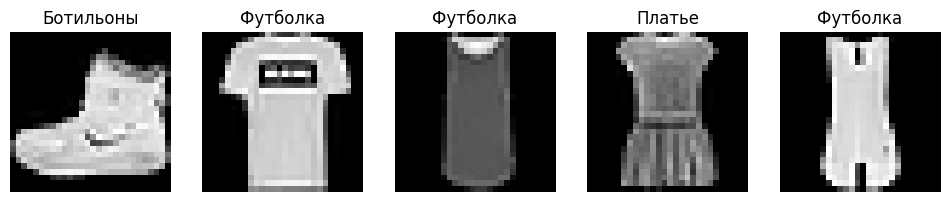

In [8]:
# Визуализируем эти первые 5 картинок в один ряд
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i in range(5):
    image, label = dataset[i]
    
    # PyTorch хранит картинки как [Каналы, Высота, Ширина]. 
    # Для отрисовки через matplotlib убираем лишнее измерение с помощью .squeeze()
    axes[i].imshow(image.squeeze(), cmap='gray')
    axes[i].set_title(classes[label])
    axes[i].axis('off')

plt.show()

In [9]:
print(dataset.targets[:2])
print(dataset.data[:2])
print(dataset.data[0].size())

tensor([9, 0])
tensor([[[0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         ...,
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0]],

        [[0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         ...,
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0]]], dtype=torch.uint8)
torch.Size([28, 28])


In [10]:
transform = torchvision.transforms.Compose([
    T.ToTensor(),
    T.Normalize((0.1307,), (0.3081,)),
])

In [11]:
train_set = FashionMNIST('.FashionMNIST', transform=transform, train=True, download=True)
val_set = FashionMNIST('.FashionMNIST', transform=transform, train=False, download=True)

train_loader = torch.utils.data.DataLoader(
    train_set,
    batch_size     = 256,
    shuffle        = True,
    num_workers    = 0
)

val_loader = torch.utils.data.DataLoader(
    val_set,
    batch_size    = 4096,
    shuffle       = False,
    num_workers   = 0
)

100%|██████████| 26.4M/26.4M [00:04<00:00, 5.95MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 6.39MB/s]
100%|██████████| 5.15k/5.15k [00:00<?, ?B/s]


In [12]:
from IPython.display import clear_output

def plot_losses(train_losses, test_losses, train_accuracies, test_accuracies):
    clear_output()
    fig, axs = plt.subplots(1, 2, figsize=(13, 4))
    axs[0].plot(range(1, len(train_losses) + 1), train_losses, label='train')
    axs[0].plot(range(1, len(test_losses) + 1), test_losses, label='test')
    axs[0].set_ylabel('loss')

    axs[1].plot(range(1, len(train_accuracies) + 1), train_accuracies, label='train')
    axs[1].plot(range(1, len(test_accuracies) + 1), test_accuracies, label='test')
    axs[1].set_ylabel('accuracy')

    for ax in axs:
        ax.set_xlabel('epoch')
        ax.legend()

    plt.show()

In [13]:
def training_epoch(model, optimizer, criterion, train_loader, tqdm_desc, wandb_project=None):
    """Одна эпоха обучения"""
    train_loss, train_accuracy = 0.0, 0.0
    model.train()
    for images, labels in tqdm(train_loader, desc=tqdm_desc): # подгрузили текстовый индикатор использования
        #images = images.to(device)
        #labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.shape[0]
        train_accuracy += (logits.argmax(dim=1) == labels).sum().item()

        if wandb_project:
            metrics = {
                "batch-train/loss": loss.item()
            }
            wandb.log(metrics)

    train_loss /= len(train_loader.dataset)
    train_accuracy /= len(train_loader.dataset)
    return train_loss, train_accuracy


@torch.no_grad()
def validation_epoch(model, criterion, val_loader, tqdm_desc):
    """Прогнозы на валидации"""

    val_loss, val_accuracy = 0.0, 0.0
    model.eval()
    for images, labels in tqdm(val_loader, desc=tqdm_desc):
        #images = images.to(device)
        #labels = labels.to(device)

        logits = model(images)
        loss = criterion(logits, labels)

        val_loss += loss.item() * images.shape[0]
        val_accuracy += (logits.argmax(dim=1) == labels).sum().item()

    val_loss /= len(val_loader.dataset)
    val_accuracy /= len(val_loader.dataset)
    return val_loss, val_accuracy


def train(model, optimizer, criterion, train_loader, val_loader, num_epochs, scheduler=None, wandb_project=None):
    """Обучение модели"""
    train_losses, train_accuracies = [], []
    val_losses, val_accuracies = [], []

    # подключаем wandb
    if wandb_project:
        wandb.init(project=wandb_project)
        wandb.watch(model)

    for epoch in range(1, num_epochs + 1):
        train_loss, train_accuracy = training_epoch(
            model, optimizer, criterion, train_loader,
            tqdm_desc=f'Training {epoch}/{num_epochs}',
            wandb_project=wandb_project
        )
        val_loss, val_accuracy = validation_epoch(
            model, criterion, val_loader,
            tqdm_desc=f'Validating {epoch}/{num_epochs}'
        )

        train_losses.append(train_loss)
        train_accuracies.append(train_accuracy)
        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)

        # функция для смены lr по расписанию
        if scheduler is not None:
            scheduler.step()

        if wandb_project:
            metrics = {
                "train/loss": train_loss / len(train_loader.dataset),
                "train/accuracy": train_accuracy / len(train_loader.dataset),
                "val/loss": val_loss,
                "val/accuracy": val_accuracy
            }
            wandb.log(metrics)
        else:
          plot_losses(train_losses, val_losses, train_accuracies, val_accuracies)

    # печатаем метрики
    print(f"Epoch: {epoch}, loss: {np.mean(val_loss)}, accuracy: {np.mean(val_accuracy)}")

In [14]:
from torch import nn

In [15]:
class FcNet(nn.Module):

    def __init__(self, input_shape, hide_neurons=32, num_classes=10):
        super().__init__()
        self.model = nn.Sequential(

            nn.Flatten(),
            nn.Linear(input_shape, hide_neurons),
            nn.ReLU(),
            nn.Linear(hide_neurons, hide_neurons // 2),
            nn.ReLU(),
            nn.Linear(hide_neurons // 2, num_classes)
            
        )

    def forward(self, x):
        return self.model(x)

In [16]:
IMG_SIZE = 28
NUM_EPOCH = 5

model_fc = FcNet(IMG_SIZE**2)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_fc.parameters(), lr=0.01, momentum=0)

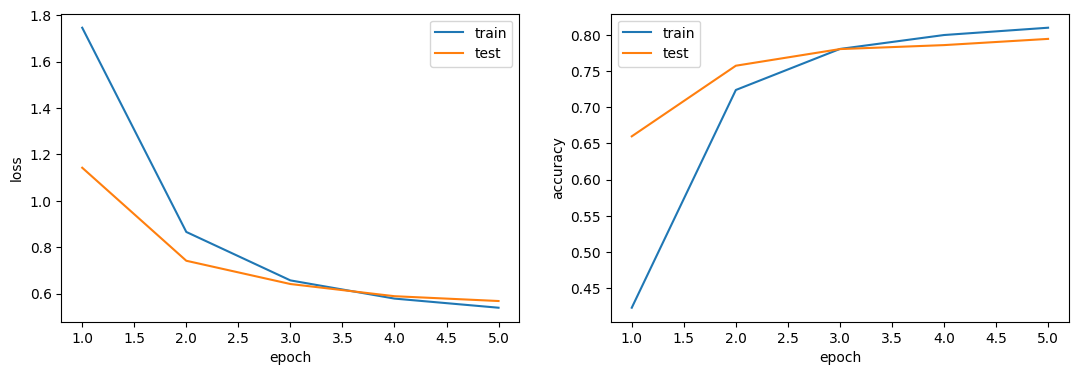

Epoch: 5, loss: 0.5678601017951965, accuracy: 0.7946


In [17]:
train(

    model_fc, optimizer, criterion,
    train_loader, val_loader,
    NUM_EPOCH
    
)

In [18]:
def predict(model, val_loader):
    X, y, logit = [], [], []
    model.eval()
    for batch_num, (x_batch, y_batch) in enumerate(val_loader):
        X.extend(x_batch)
        y.extend(y_batch)
        # x_batch = x_batch.to(device)

        with torch.no_grad():
            logits = model(x_batch)

        logit.extend(torch.max(logits, 1)[1].cpu().numpy())
    return np.array(X), np.array(y), np.array(logit)

In [19]:
X_test, y_test, y_pred = predict(model_fc, val_loader)

In [20]:
errors = y_test != y_pred

X_err = X_test[errors]
y_err = y_test[errors]
y_pred_err = y_pred[errors]

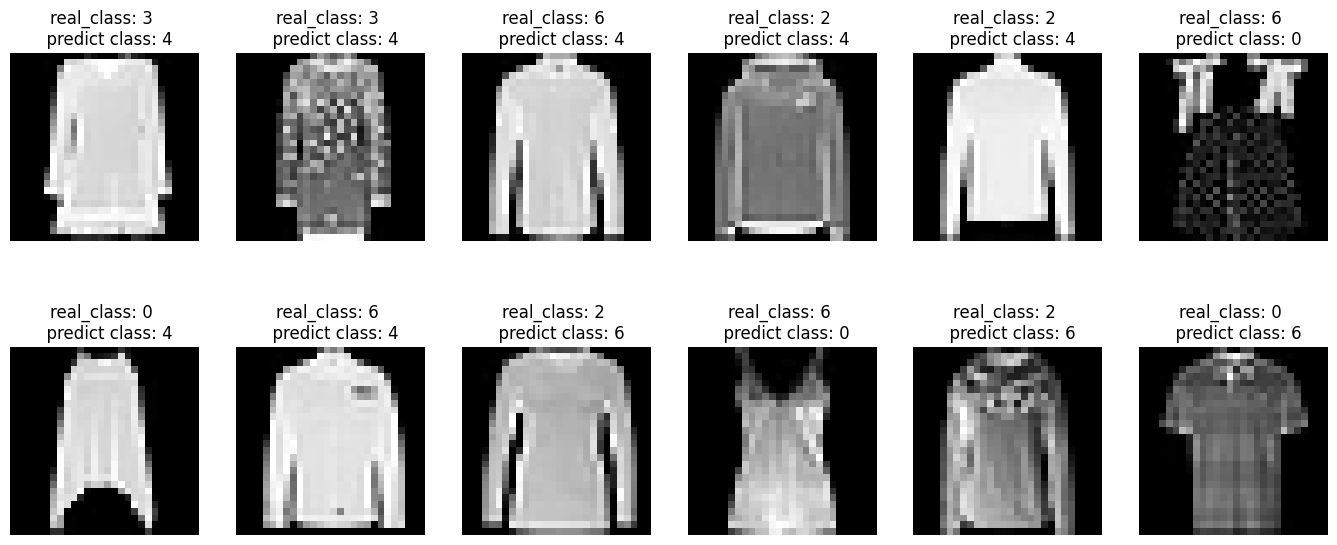

In [21]:
cols = 6
rows = 2
fig = plt.figure(figsize=(3 * cols - 1, 4 * rows - 1))
for i in range(cols):
    for j in range(rows):
        random_index = np.random.randint(0, len(y_err))
        ax = fig.add_subplot(rows, cols, i * rows + j + 1)
        ax.grid('off')
        ax.axis('off')
        ax.imshow(np.transpose(X_err[random_index], (1, 2, 0)), cmap='gray')
        ax.set_title('real_class: {} \n  predict class: {}'.format(y_err[random_index], y_pred_err[random_index]))
plt.show()

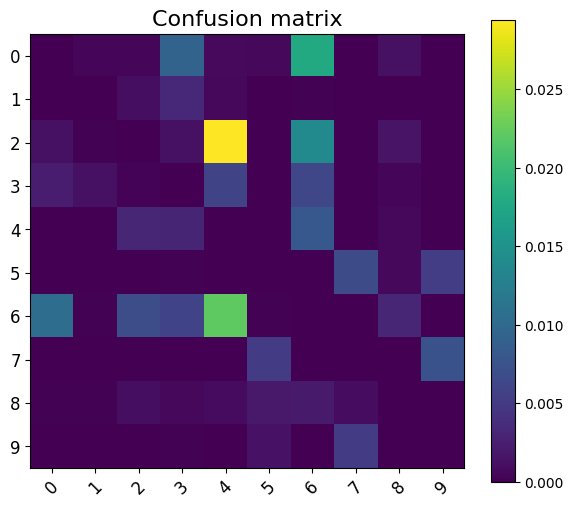

In [22]:
from sklearn.metrics import confusion_matrix, accuracy_score

cm = confusion_matrix(y_test, y_pred, normalize='all')
cm = cm - np.eye(10)*cm.diagonal()

plt.figure(figsize=(7, 6))
plt.title('Confusion matrix', fontsize=16)
plt.imshow(cm)
plt.xticks(np.arange(10), np.arange(10), rotation=45, fontsize=12)
plt.yticks(np.arange(10), np.arange(10), fontsize=12)
plt.colorbar()
plt.show();

In [23]:
class ConvNet(nn.Module):

    def __init__(self, image_channels=1):
        super().__init__()
        
        self.encoder = nn.Sequential(
            
            nn.Conv2d(in_channels=image_channels, out_channels=4,
                      kernel_size=3, padding='same'),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(in_channels=4, out_channels=8,
                      kernel_size=3, padding='same'),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(in_channels=8, out_channels=16,
                      kernel_size=3, padding='same'),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.head = nn.Sequential(
            nn.Linear(in_features=144, out_features=32),
            nn.ReLU(),
            nn.Linear(in_features=32, out_features=10)
        )

    def forward(self, x):
        out = self.encoder(x)
        out = nn.Flatten()(out)
        out = self.head(out)
        return out

    def get_embedding(self, x):
        out = self.encoder(x)
        return nn.Flatten()(out)

In [24]:
model_cnn = ConvNet()
optimizer = torch.optim.SGD(model_cnn.parameters(), lr=0.01, momentum=0)

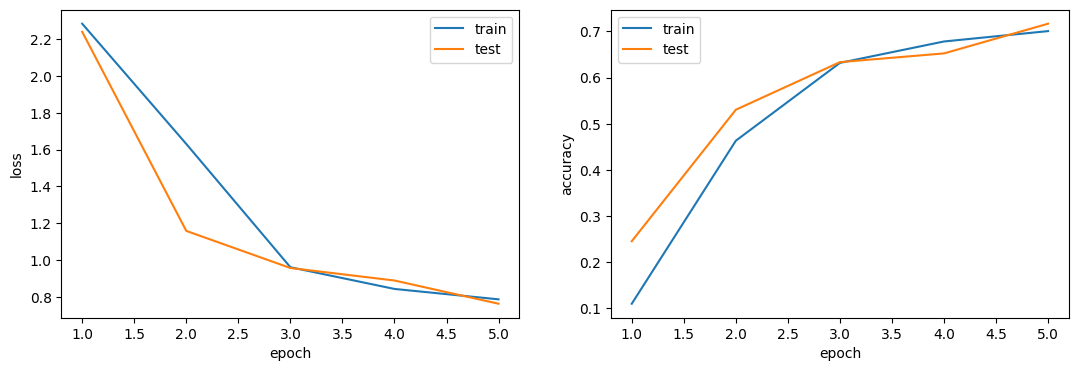

Epoch: 5, loss: 0.7622668222427368, accuracy: 0.7168


In [25]:
train(model_cnn, optimizer, criterion, train_loader, val_loader, NUM_EPOCH)

In [26]:
X_test, y_test, y_pred = predict(model_cnn, val_loader)

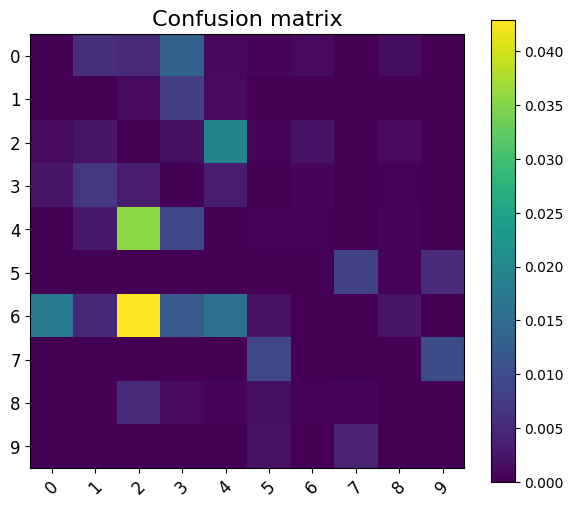

In [27]:
cm = confusion_matrix(y_test, y_pred, normalize='all')
cm = cm - np.eye(10)*cm.diagonal()

plt.figure(figsize=(7, 6))
plt.title('Confusion matrix', fontsize=16)
plt.imshow(cm)
plt.xticks(np.arange(10), np.arange(10), rotation=45, fontsize=12)
plt.yticks(np.arange(10), np.arange(10), fontsize=12)
plt.colorbar()
plt.show();

In [28]:
model_cnn_adam = ConvNet()
optimizer = torch.optim.Adam(model_cnn_adam.parameters(), lr=1e-3)

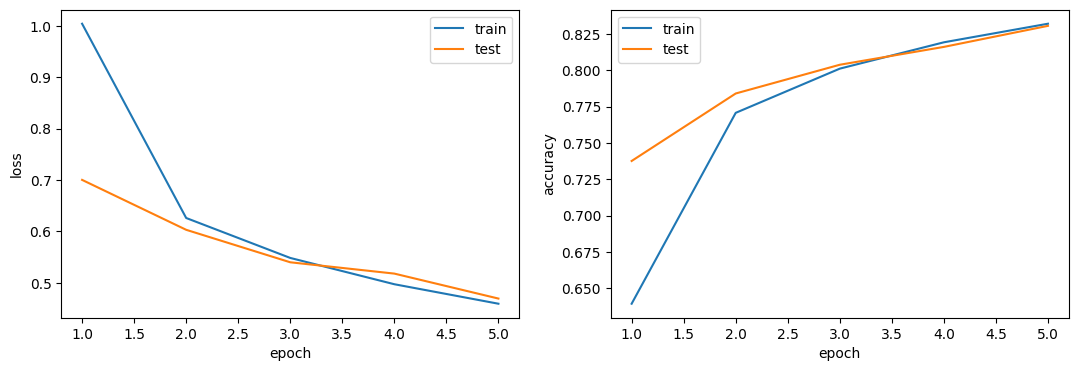

Epoch: 5, loss: 0.4691881244182587, accuracy: 0.8307


In [29]:
train(model_cnn_adam, optimizer, criterion, train_loader, val_loader, NUM_EPOCH)

In [31]:
X_test, y_test, y_pred = predict(model_cnn_adam, val_loader)

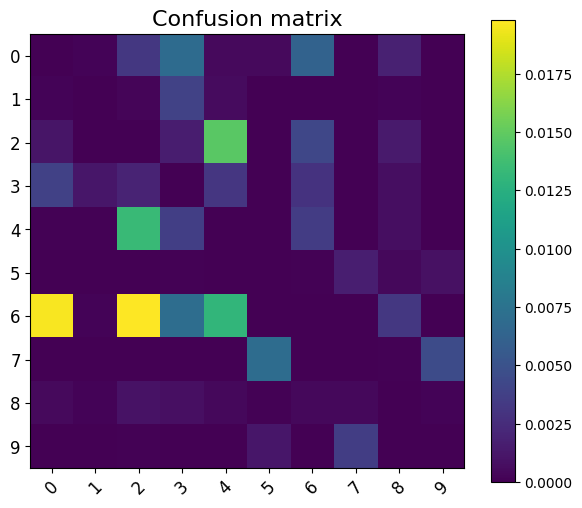

In [32]:
cm = confusion_matrix(y_test, y_pred, normalize='all')
cm = cm - np.eye(10)*cm.diagonal()

plt.figure(figsize=(7, 6))
plt.title('Confusion matrix', fontsize=16)
plt.imshow(cm)
plt.xticks(np.arange(10), np.arange(10), rotation=45, fontsize=12)
plt.yticks(np.arange(10), np.arange(10), fontsize=12)
plt.colorbar()
plt.show();